In [ ]:

!pip install gymnasium
!pip install "stable-baselines3[extra]>=2.0.0a4"


!pip install gym==0.26.2


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

import os, sys, io, zipfile, urllib.request

GYM_LATTICE_DIR = os.path.abspath("gym-lattice-master")   
if not os.path.isdir(os.path.join(GYM_LATTICE_DIR, "gym_lattice")):
    url = "https://github.com/ljvmiranda921/gym-lattice/archive/refs/heads/master.zip"
    print("Downloading", url)
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(os.path.dirname(GYM_LATTICE_DIR))
sys.path.insert(0, GYM_LATTICE_DIR)
print("gym-lattice source:", GYM_LATTICE_DIR)

gym-lattice source: c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

import gymnasium as gym
from gymnasium import spaces
import stable_baselines3
from stable_baselines3 import DQN
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor


try:
    from gym_lattice.envs import Lattice2DEnv
except Exception as e:
    import sys
    print("Old `gym` import failed (", e, ") -> using gymnasium for gym-lattice's imports")
    for k in [m for m in sys.modules if m == "gym" or m.startswith("gym.") or m.startswith("gym_lattice")]:
        del sys.modules[k]
    import gymnasium.envs.registration
    sys.modules["gym"] = gymnasium
    sys.modules["gym.envs"] = gymnasium.envs
    sys.modules["gym.envs.registration"] = gymnasium.envs.registration
    from gym_lattice.envs import Lattice2DEnv
from gym_lattice.envs.lattice2d_env import ACTION_TO_STR   # {0:'L', 1:'D', 2:'U', 3:'R'}

print(f"{gym.__version__=}")
print(f"{stable_baselines3.__version__=}")
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

gym.__version__='1.4.0'
stable_baselines3.__version__='2.9.0'
Device: cuda


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [ ]:
SEQUENCES = {
    "20mer-A": "HPHPPHHPHPPHPHHPPHPH",
    "20mer-B": "HHHPPHPHPHPPHPHPHPPH",
}
BEST_KNOWN = {"20mer-A": -9, "20mer-B": -10}

BASE_DIR = "HP20_DQN"         
TOTAL_TIMESTEPS = 500_000      
SAVE_INTERVAL = 50_000         
N_ENVS = 4
SEED = 0

def run_dirs(name):
    d = {k: os.path.join(BASE_DIR, name, k) for k in ("gym", "models", "tb")}
    for p in d.values():
        os.makedirs(p, exist_ok=True)
    return d

In [ ]:
from math import floor
from gym_lattice.envs import Lattice2DEnv   


def hp_energy(chain, seq):
    
    coords = list(chain.keys())
    index = {c: i for i, c in enumerate(coords)}
    contacts = 0
    for i, (x, y) in enumerate(coords):
        if seq[i] != 'H':
            continue
        for nb in ((x + 1, y), (x, y + 1)):          
            j = index.get(nb)
            if j is not None and abs(i - j) > 1 and seq[j] == 'H':
                contacts += 1
    return -contacts

#old gym -> gymnasium with SB3
class GymLatticeCompat(gym.Env):
    
    metadata = {"render_modes": ["human", "ansi"]}
    N_CHANNELS = 5

    def __init__(self, seq, collision_penalty=-2, trap_penalty=0.5,
                 max_steps=None, fix_final_trap=True):
        super().__init__()
        self.seq = seq.upper()
        self.n = len(self.seq)
        self.trap_penalty = trap_penalty
        self.fix_final_trap = fix_final_trap
        self.max_steps = max_steps or 4 * self.n
        self.lattice = Lattice2DEnv(self.seq, collision_penalty=collision_penalty,
                                    trap_penalty=trap_penalty)
        self.size = 2 * self.n + 1
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=0.0, high=1.0,
                                            shape=(self.N_CHANNELS, self.size, self.size),
                                            dtype=np.float32)
        self.steps = 0

  
    def _obs(self):
        chain = self.lattice.state
        obs = np.zeros((self.N_CHANNELS, self.size, self.size), dtype=np.float32)
        coords = list(chain.keys())
        hx, hy = coords[-1]                       
        c = self.n                                
        for i, (x, y) in enumerate(coords):
            row, col = c - (y - hy), c + (x - hx) 
            obs[0 if chain[(x, y)] == 'H' else 1, row, col] = 1.0
            obs[2, row, col] = i / (self.n - 1)
        placed = len(coords)
        if placed < self.n:
            obs[3, :, :] = 1.0 if self.seq[placed] == 'H' else 0.0
        obs[4, :, :] = placed / self.n
        return obs

    def _info(self, extra=None):
        chain = self.lattice.state
        info = {
            "chain_length": len(chain),
            "complete": len(chain) == self.n,
            "energy": hp_energy(chain, self.seq),
            "collisions": self.lattice.collisions,
            "actions": "".join(ACTION_TO_STR[a] for a in self.lattice.actions),
        }
        if extra:
            info.update(extra)
        return info

    #  Gymnasium API
    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.lattice.reset()
        self.steps = 0
        return self._obs(), self._info()

    def step(self, action):
        _, reward, done, linfo = self.lattice.step(int(action))
        self.steps += 1
        complete = linfo["chain_length"] == self.n
        if self.fix_final_trap and linfo["is_trapped"] and complete:
            reward += floor(self.n * self.trap_penalty)   
        terminated = bool(done)
        truncated = (not terminated) and self.steps >= self.max_steps
        info = self._info({"trapped": bool(linfo["is_trapped"]) and not complete})
        return self._obs(), float(reward), terminated, truncated, info

    def render(self, mode="human"):
        return self.lattice.render(mode=mode)   

Random Agent

In [6]:
env = GymLatticeCompat(SEQUENCES["20mer-A"])
print("Observation space:", env.observation_space.shape)
print("Action space:", env.action_space, "->", ACTION_TO_STR)

rng = np.random.default_rng(SEED)
energies = []
for ep in range(2000):
    obs, info = env.reset()
    done = False
    while not done:
        obs, r, term, trunc, info = env.step(int(rng.integers(4)))
        done = term or trunc
    if info["complete"]:
        energies.append(info["energy"])
print(f"Random agent: {len(energies)}/2000 complete folds, "
      f"mean energy {np.mean(energies):.2f}, best energy {min(energies)}")

env.render()   # last random fold, drawn by gym-lattice

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


Observation space: (5, 41, 41)
Action space: Discrete(4) -> {0: 'L', 1: 'D', 2: 'U', 3: 'R'}
Random agent: 1847/2000 complete folds, mean energy -1.33, best energy -7
  (Up)
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
******************PH********

In [ ]:
class SaveOnIntervalCallback(BaseCallback):
    def __init__(self, save_interval: int, save_path: str, verbose=1):
        super().__init__(verbose)
        self.save_interval = save_interval
        self.save_path = save_path

    def _on_step(self) -> bool:
        
        if self.num_timesteps % self.save_interval < self.training_env.num_envs:
            save_file = os.path.join(self.save_path, f'model_{self.num_timesteps}')
            self.model.save(save_file)
            if self.verbose > 0:
                print(f'Saving model to {save_file}.zip')
        return True


class FoldTrackerCallback(BaseCallback):
    # Tracks energies of completed folds and the best fold
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.best_energy = 0
        self.best_actions = ""
        self.best_timestep = None
        self.history = []          # (timestep, energy) 
    def _on_step(self) -> bool:
        for done, info in zip(self.locals["dones"], self.locals["infos"]):
            if done and info.get("complete"):
                e = info["energy"]
                self.history.append((self.num_timesteps, e))
                if e < self.best_energy:
                    self.best_energy, self.best_actions = e, info["actions"]
                    self.best_timestep = self.num_timesteps
                    if self.verbose:
                        print(f"[{self.num_timesteps:>8}] new best energy {e}  ({self.best_actions})")
        self.logger.record("fold/best_energy", self.best_energy)
        return True


CNN feature extractor


In [ ]:
class CustomCNN(BaseFeaturesExtractor):
    def __init__(self, observation_space: gym.spaces.Box, features_dim: int = 256):
        super(CustomCNN, self).__init__(observation_space, features_dim)
        n_input_channels = observation_space.shape[0]      # 5 channels

        # Define the convolutional layers
        self.cnn = nn.Sequential(
            nn.Conv2d(n_input_channels, 32, kernel_size=3, stride=1, padding=1),  
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),                 
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1),                 
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),                
            nn.ReLU(),
            nn.Flatten(),
        )

        with torch.no_grad():
            n_flatten = self.cnn(
                torch.as_tensor(observation_space.sample()[None]).float()
            ).shape[1]

        # Define the linear layer that follows the convolutional layers
        self.linear = nn.Sequential(nn.Linear(n_flatten, features_dim), nn.ReLU())

        # Kaiming (He) initialisation, suited to ReLU activations
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        return self.linear(self.cnn(observations))

In [ ]:
def make_model(seq, dirs):
    env = make_vec_env(lambda: GymLatticeCompat(seq), n_envs=N_ENVS, seed=SEED,
                       monitor_dir=dirs["gym"],
                       monitor_kwargs={"info_keywords": ("energy", "complete", "collisions")})
    model = DQN(
        env=env,
        policy='CnnPolicy',
        verbose=0,
        learning_rate=5e-4,
        buffer_size=50_000,
        learning_starts=10_000,
        batch_size=32,
        gamma=0.98,
        train_freq=4,
        gradient_steps=1,
        target_update_interval=1_000,
        exploration_fraction=0.5,     
        exploration_initial_eps=1.0,
        exploration_final_eps=0.01,
        tensorboard_log=dirs["tb"],
        seed=SEED,
        policy_kwargs={'features_extractor_class': CustomCNN,
                       'features_extractor_kwargs': {'features_dim': 256},
                       'net_arch': [256],
                       'normalize_images': False})   
    return model


_tmp_model = make_model(SEQUENCES["20mer-A"], run_dirs("_tmp"))
print(_tmp_model.policy)
del _tmp_model

CnnPolicy(
  (q_net): QNetwork(
    (features_extractor): CustomCNN(
      (cnn): Sequential(
        (0): Conv2d(5, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (3): ReLU()
        (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        (5): ReLU()
        (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (7): ReLU()
        (8): Flatten(start_dim=1, end_dim=-1)
      )
      (linear): Sequential(
        (0): Linear(in_features=15488, out_features=256, bias=True)
        (1): ReLU()
      )
    )
    (q_net): Sequential(
      (0): Linear(in_features=256, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=4, bias=True)
    )
  )
  (q_net_target): QNetwork(
    (features_extractor): CustomCNN(
      (cnn): Sequential(
        (0): Conv2d(5, 32, kernel_size=(3, 3), stride=(1,

Training

In [10]:
trackers = {}
for name, seq in SEQUENCES.items():
    print(f"\n===== Training on {name}: {seq} =====")
    dirs = run_dirs(name)
    model = make_model(seq, dirs)
    save_callback = SaveOnIntervalCallback(SAVE_INTERVAL, dirs["models"], verbose=0)
    tracker = FoldTrackerCallback(verbose=1)
    model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=[save_callback, tracker],
                tb_log_name=name, progress_bar=True)
    model.save(os.path.join(dirs["models"], f"model_{model.num_timesteps}"))
    trackers[name] = tracker
    print(f"{name}: best energy during training = {tracker.best_energy} "
          f"(best known {BEST_KNOWN[name]}) at step {tracker.best_timestep}")

c:\Users\WorkPlace\AppData\Local\Programs\Python\Python313\Lib\site-packages\rich\live.py:260: UserWarning: install
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

[     100] new best energy -2  (ULUURRURDRUULURUULL)

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning:
WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')

[     352] new best energy -3  (RDDLULUURRRDDRDRDDR)


===== Training on 20mer-A: HPHPPHHPHPPHPHHPPHPH =====


...

[   24204] new best energy -6  (RDLDRRRRUULDLUULLLD)

[  131128] new best energy -7  (DLDLUURURURDDDDLDDL)

[  222984] new best energy -8  (URURDDLDLDLUUUULLDR)

[  343216] new best energy -9  (LUURDRDDLDLULUULLDR)

20mer-B: best energy during training = -9 (best known -10) at step 343216


Learning curves


20mer-A: 24139 training episodes, 98.2% completed without trapping
20mer-B: 24128 training episodes, 98.6% completed without trapping


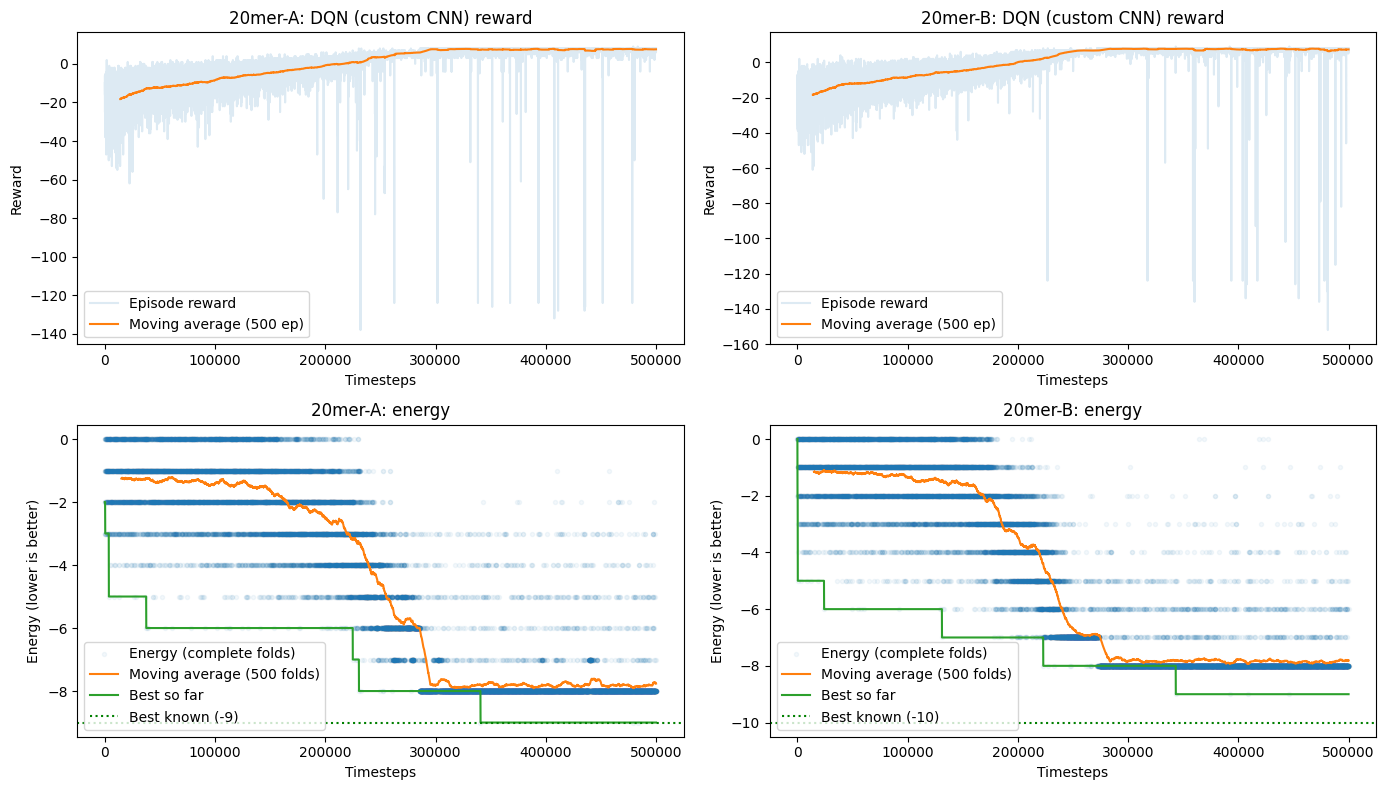

In [11]:
def moving_average(values, window):
    weights = np.repeat(1.0, window) / window
    return np.convolve(values, weights, 'valid')

window = 500
fig, axes = plt.subplots(2, len(SEQUENCES), figsize=(7 * len(SEQUENCES), 8), squeeze=False)
for col, name in enumerate(SEQUENCES):
    res = load_results(run_dirs(name)["gym"])
    x, y = ts2xy(res, 'timesteps')
    ax = axes[0, col]
    ax.plot(x, y, alpha=0.15, label='Episode reward')
    if len(y) >= window:
        ax.plot(x[window-1:], moving_average(y, window), label=f'Moving average ({window} ep)')
    ax.set_title(f'{name}: DQN (custom CNN) reward'); ax.set_xlabel('Timesteps'); ax.set_ylabel('Reward'); ax.legend()

    comp = res["complete"].astype(bool).values
    xe, ye = x[comp], res["energy"].values[comp]
    ax = axes[1, col]
    ax.plot(xe, ye, '.', alpha=0.05, label='Energy (complete folds)')
    if len(ye) >= window:
        ax.plot(xe[window-1:], moving_average(ye, window), label=f'Moving average ({window} folds)')
    ax.plot(xe, np.minimum.accumulate(ye), label='Best so far')
    ax.axhline(BEST_KNOWN[name], color='green', linestyle=':', label=f'Best known ({BEST_KNOWN[name]})')
    ax.set_title(f'{name}: energy'); ax.set_xlabel('Timesteps'); ax.set_ylabel('Energy (lower is better)'); ax.legend()
    print(f"{name}: {len(y)} training episodes, {comp.mean():.1%} completed without trapping")
plt.tight_layout(); plt.show()

Evaluate 

20mer-A – saved models (timesteps): ['50000', '100000', '150000', '200000', '250000', '300000', '350000', '400000', '450000', '500000']

=== beginning: model after 50,000 timesteps | greedy fold: complete, energy 0, collisions 0, actions DLLLLLLLLLLLLLLLLLL ===
  (Left)
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
***************

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')



=== middle: model after 300,000 timesteps | greedy fold: complete, energy -8, collisions 0, actions ULULDDLUULDDDRDRURU ===
  (Up)
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
****************PPPP*********************
****************HHHHP********************
****************PPHHH*******

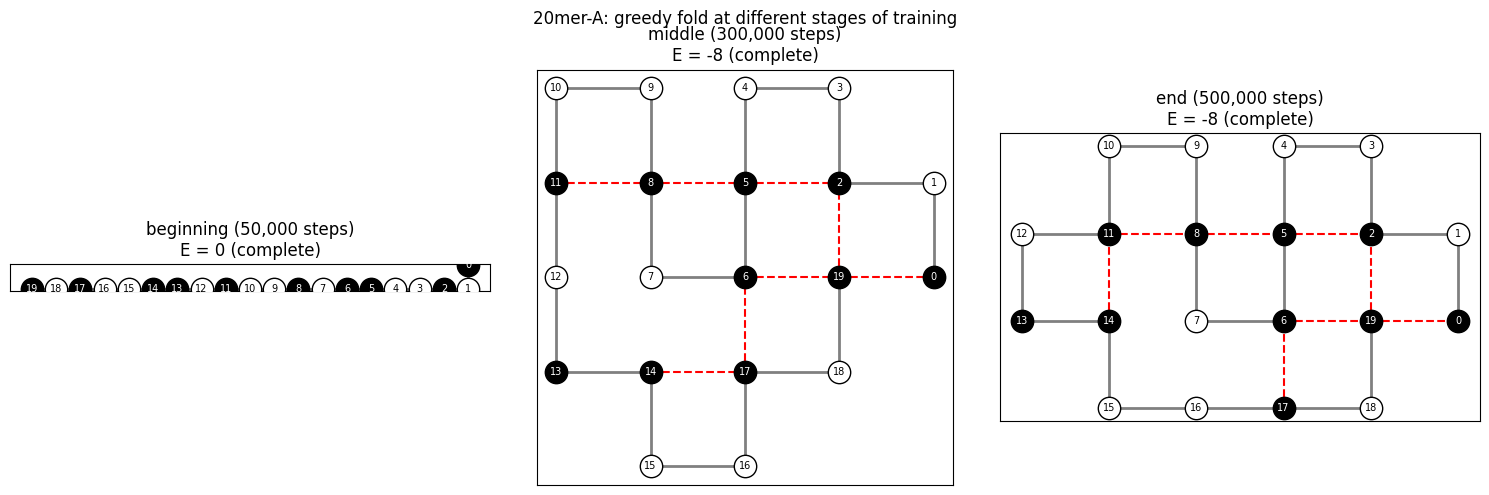

20mer-B – saved models (timesteps): ['50000', '100000', '150000', '200000', '250000', '300000', '350000', '400000', '450000', '500000']

=== beginning: model after 50,000 timesteps | greedy fold: complete, energy 0, collisions 0, actions RRRRRRRRRRRRRURRRRU ===
  (Up)
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************

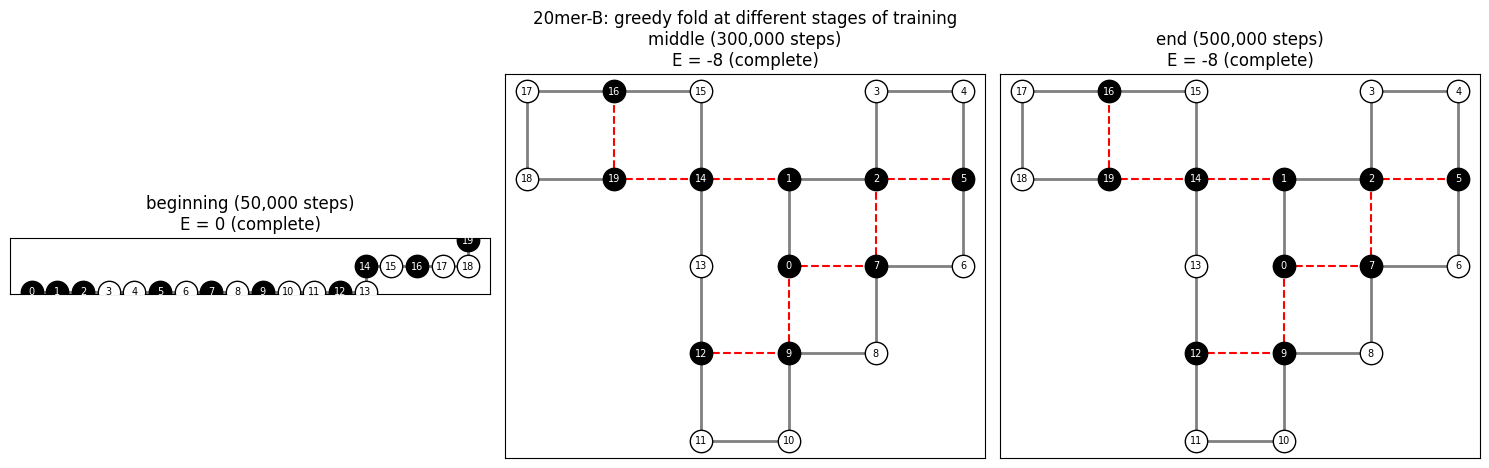

In [ ]:
def run_episode(model, seq, eps=0.0, rng=None):
    
    env = GymLatticeCompat(seq)
    obs, info = env.reset()
    rng = rng or np.random.default_rng()
    done = False
    while not done:
        if rng.random() < eps:
            action = int(rng.integers(4))
        else:
            action, _ = model.predict(obs, deterministic=True)
        obs, r, term, trunc, info = env.step(int(action))
        done = term or trunc
    return env, info


def plot_fold(chain, seq, title="", ax=None):
    coords = np.array(list(chain.keys()))
    ax = ax or plt.gca()
    index = {tuple(c): i for i, c in enumerate(coords)}
    for i, (x, y) in enumerate(coords):          # H-H contacts
        for nb in ((x + 1, y), (x, y + 1)):
            j = index.get(nb)
            if seq[i] == 'H' and j is not None and abs(i - j) > 1 and seq[j] == 'H':
                ax.plot([x, nb[0]], [y, nb[1]], 'r--', lw=1.5, zorder=1)
    ax.plot(coords[:, 0], coords[:, 1], '-', color='grey', lw=2, zorder=2)
    for i, (x, y) in enumerate(coords):
        ax.scatter(x, y, s=260, zorder=3, edgecolors='k',
                   c='black' if seq[i] == 'H' else 'white')
        ax.annotate(str(i), (x, y), color='white' if seq[i] == 'H' else 'black',
                    ha='center', va='center', fontsize=7, zorder=4)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)


def get_model_identifiers(models_dir):
    files = os.listdir(models_dir)
    model_files = [f for f in files if f.startswith('model_') and f.endswith('.zip')]
    identifiers = [f.split('_')[1].replace('.zip', '') for f in model_files]
    return [i for i in identifiers if i.isdigit()]

def find_key_identifiers(identifiers):
    identifiers.sort(key=int)
    return identifiers[0], identifiers[len(identifiers) // 2], identifiers[-1]

def view(name):
    seq, models_dir = SEQUENCES[name], run_dirs(name)["models"]
    identifiers = get_model_identifiers(models_dir)
    stages = find_key_identifiers(identifiers)
    print(f"{name} – saved models (timesteps):", sorted(identifiers, key=int))
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, stage, identifier in zip(axes, ["beginning", "middle", "end"], stages):
        model = DQN.load(os.path.join(models_dir, f'model_{identifier}'))
        env, info = run_episode(model, seq, eps=0.0)
        status = "complete" if info["complete"] else ("trapped" if info.get("trapped") else "step limit")
        print(f"\n=== {stage}: model after {int(identifier):,} timesteps | greedy fold: "
              f"{status}, energy {info['energy']}, collisions {info['collisions']}, actions {info['actions']} ===")
        env.render()
        plot_fold(env.lattice.state, seq, f"{stage} ({int(identifier):,} steps)\nE = {info['energy']} ({status})", ax)
    plt.suptitle(f"{name}: greedy fold at different stages of training"); plt.tight_layout(); plt.show()

for name in SEQUENCES:
    view(name)

Decision videos: how the agent chooses each move (early / middle / final / best)

In [13]:
import base64
from pathlib import Path
from matplotlib import animation
from IPython import display as ipythondisplay

ACTION_NAMES = ["Left", "Down", "Up", "Right"]          # gym-lattice action order 0..3
MOVES = {0: (-1, 0), 1: (0, -1), 2: (0, 1), 3: (1, 0)}


def q_values(model, obs):
    """Q(s, a) for the 4 actions from the trained DQN network."""
    obs_t, _ = model.policy.obs_to_tensor(obs)
    with torch.no_grad():
        return model.q_net(obs_t)[0].cpu().numpy()


def record_decisions(model, seq, max_repeat_collisions=3):
    """Run one greedy episode and record, for every decision, the chain, the Q-values
    and the chosen action. A greedy agent that hits a collision sees the same state again
    and repeats the same move, so we stop after a few identical collisions."""
    env = GymLatticeCompat(seq)
    obs, info = env.reset()
    frames, repeat = [], 0
    while True:
        q = q_values(model, obs)
        action = int(np.argmax(q))
        chain_before = list(env.lattice.state.items())
        hx, hy = chain_before[-1][0]
        target = (hx + MOVES[action][0], hy + MOVES[action][1])
        obs, r, term, trunc, info = env.step(action)
        collided = len(env.lattice.state) == len(chain_before)
        repeat = repeat + 1 if collided else 0
        frames.append(dict(chain=chain_before, q=q, action=action, target=target,
                           collided=collided, reward=r, energy_after=info["energy"],
                           chain_after=list(env.lattice.state.items())))
        if term or trunc or repeat >= max_repeat_collisions:
            status = ("complete" if info["complete"] else
                      "trapped" if info.get("trapped") else
                      "stuck repeating a collision" if repeat >= max_repeat_collisions else "step limit")
            return frames, info, status


def _draw_chain(ax, chain, seq, lims, target=None, collided=False, action=None):
    ax.clear()
    coords = [c for c, _ in chain]
    index = {c: i for i, c in enumerate(coords)}
    for i, (x, y) in enumerate(coords):                       # H-H contacts
        for nb in ((x + 1, y), (x, y + 1)):
            j = index.get(nb)
            if seq[i] == 'H' and j is not None and abs(i - j) > 1 and seq[j] == 'H':
                ax.plot([x, nb[0]], [y, nb[1]], 'r--', lw=1.5, zorder=1)
    xs, ys = zip(*coords)
    ax.plot(xs, ys, '-', color='grey', lw=2, zorder=2)
    for i, (x, y) in enumerate(coords):
        ax.scatter(x, y, s=220, zorder=3, edgecolors='k', c='black' if seq[i] == 'H' else 'white')
        ax.annotate(str(i), (x, y), color='white' if seq[i] == 'H' else 'black',
                    ha='center', va='center', fontsize=7, zorder=4)
    hx, hy = coords[-1]
    ax.scatter(hx, hy, s=420, facecolors='none', edgecolors='orange', lw=2.5, zorder=5)   # current head
    if target is not None:
        ax.annotate("", xy=target, xytext=(hx, hy),
                    arrowprops=dict(arrowstyle="->", lw=2.5, color='red' if collided else 'tab:blue'), zorder=6)
        if collided:
            ax.scatter(*target, marker='x', s=300, c='red', lw=3, zorder=7)
    ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1])
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])


def make_decision_video(model, seq, title, out_path, fps=2):
    frames, info, status = record_decisions(model, seq)
    all_coords = [c for f in frames for c, _ in f["chain_after"]] + [f["target"] for f in frames]
    xs, ys = zip(*all_coords)
    pad = 1
    lims = ((min(xs) - pad, max(xs) + pad), (min(ys) - pad, max(ys) + pad))

    fig, (ax_fold, ax_q) = plt.subplots(1, 2, figsize=(11, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
    n_frames = len(frames) + 2                                  # + final frame held for 2 ticks

    def update(k):
        ax_q.clear()
        if k < len(frames):
            f = frames[k]
            placed = len(f["chain"])
            _draw_chain(ax_fold, f["chain"], seq, lims, f["target"], f["collided"], f["action"])
            colors = ['lightgrey'] * 4
            colors[f["action"]] = 'red' if f["collided"] else 'tab:blue'
            ax_q.bar(ACTION_NAMES, f["q"], color=colors, edgecolor='k')
            for i, v in enumerate(f["q"]):
                ax_q.text(i, v, f"{v:.2f}", ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
            ax_q.axhline(0, color='k', lw=0.8)
            ax_q.set_title("Q-values: the agent picks the highest")
            outcome = "COLLISION (-2)" if f["collided"] else f"place residue {placed} ({seq[placed]})"
            ax_fold.set_title(f"Step {k + 1}: choose {ACTION_NAMES[f['action']]} -> {outcome}\n"
                              f"energy after this move: {f['energy_after']}",
                              fontsize=10)
        else:
            _draw_chain(ax_fold, frames[-1]["chain_after"], seq, lims)
            ax_fold.set_title(f"Final: {status}, energy E = {info['energy']}", fontsize=11)
            ax_q.axis('off')
            ax_q.text(0.5, 0.5, f"Result: {status}\nE = {info['energy']}\ncollisions = {info['collisions']}\n"
                                f"moves = {info['actions']}", ha='center', va='center', fontsize=12,
                      transform=ax_q.transAxes)
        fig.suptitle(title, fontsize=13)
        return []

    anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 / fps, blit=False)
    if animation.writers.is_available("ffmpeg"):
        out_path = str(Path(out_path).with_suffix(".mp4"))
        anim.save(out_path, writer=animation.FFMpegWriter(fps=fps))
    else:                                                       # no ffmpeg (e.g. Windows) -> GIF
        out_path = str(Path(out_path).with_suffix(".gif"))
        anim.save(out_path, writer=animation.PillowWriter(fps=fps))
    plt.close(fig)
    print(f"{title}: {status}, energy {info['energy']}, collisions {info['collisions']} -> {out_path}")
    return out_path, info, status


def show_video(path):
    data = base64.b64encode(Path(path).read_bytes()).decode("ascii")
    if path.endswith(".mp4"):
        html = f'<video autoplay loop controls style="height: 420px;"><source src="data:video/mp4;base64,{data}" type="video/mp4"/></video>'
    else:
        html = f'<img src="data:image/gif;base64,{data}" style="height: 420px;"/>'
    ipythondisplay.display(ipythondisplay.HTML(html))

20mer-A: scoring every checkpoint to find the best one
    100,000 steps: complete                     E = -1
    150,000 steps: complete                     E = -2
    200,000 steps: complete                     E = -1
    250,000 steps: complete                     E = -5
    300,000 steps: complete                     E = -8
    350,000 steps: complete                     E = -8
    400,000 steps: complete                     E = -8
    450,000 steps: complete                     E = -8
     50,000 steps: complete                     E = 0
    500,000 steps: complete                     E = -8
20mer-A – early model (50,000 training steps): complete, energy 0, collisions 0 -> HP20_DQN\20mer-A\videos\dqn-20mer-A-early.gif



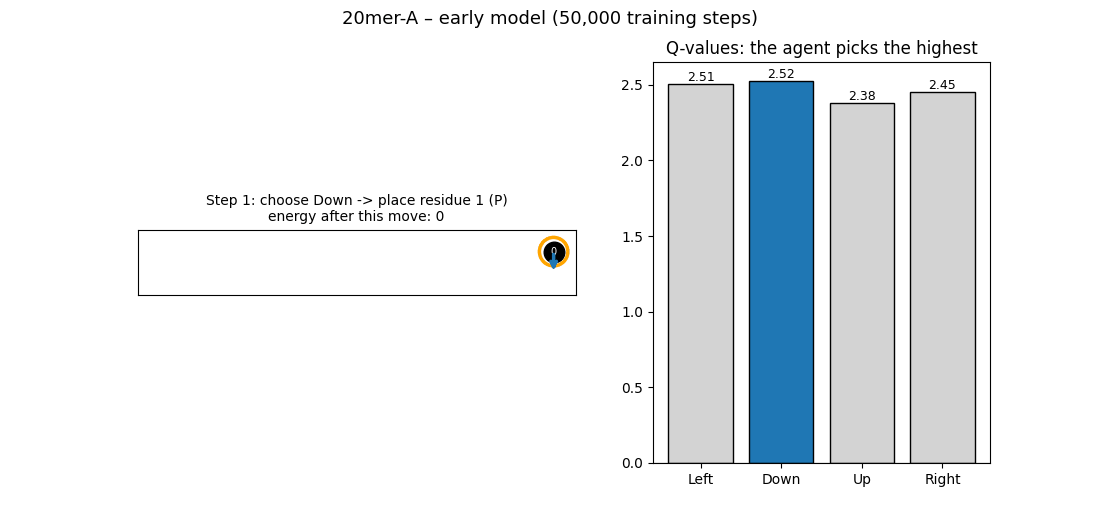

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


20mer-A – middle model (300,000 training steps): complete, energy -8, collisions 0 -> HP20_DQN\20mer-A\videos\dqn-20mer-A-middle.gif



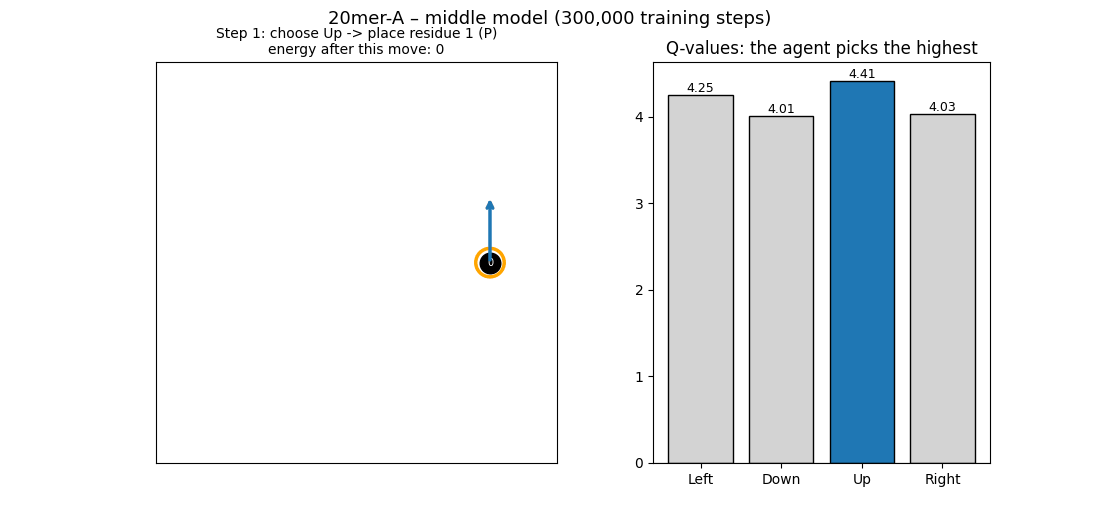

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


20mer-A – final model (500,000 training steps): complete, energy -8, collisions 0 -> HP20_DQN\20mer-A\videos\dqn-20mer-A-final.gif



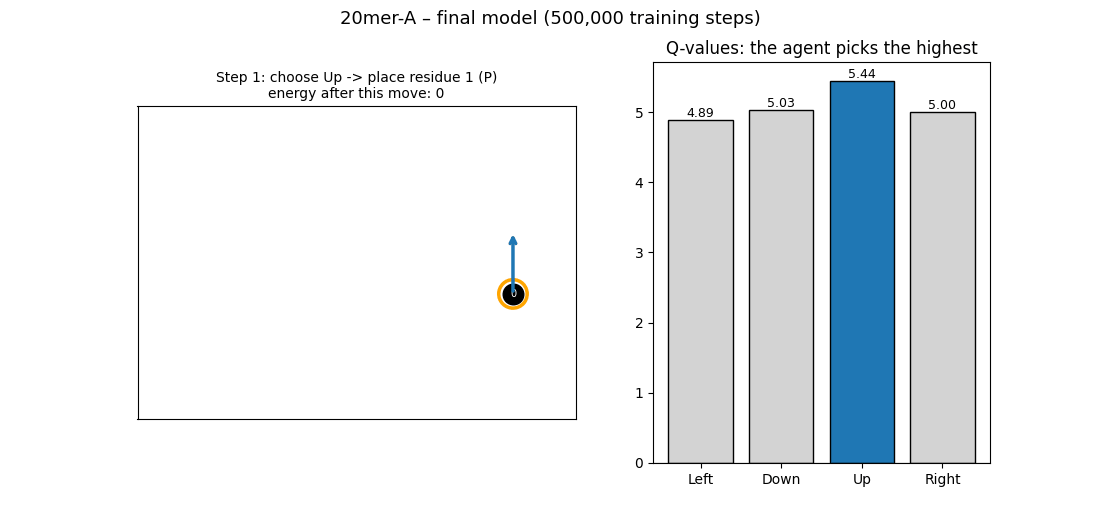

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


20mer-A – best model (500,000 training steps): complete, energy -8, collisions 0 -> HP20_DQN\20mer-A\videos\dqn-20mer-A-best.gif



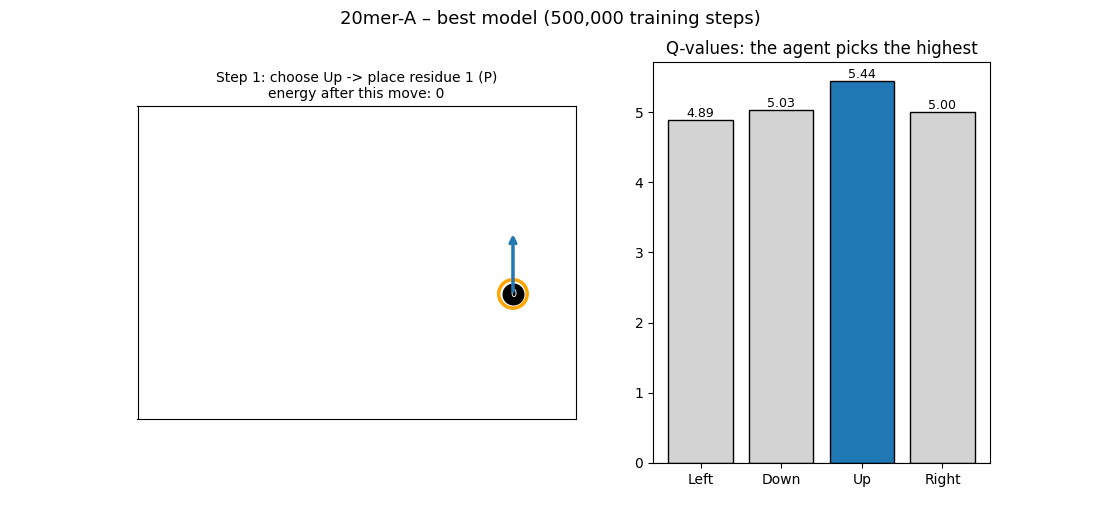

20mer-B: scoring every checkpoint to find the best one
    100,000 steps: complete                     E = -4
    150,000 steps: complete                     E = 0
    200,000 steps: complete                     E = -4
    250,000 steps: complete                     E = -7
    300,000 steps: complete                     E = -8
    350,000 steps: complete                     E = -8
    400,000 steps: complete                     E = -8
    450,000 steps: complete                     E = -8
     50,000 steps: complete                     E = 0
    500,000 steps: complete                     E = -8
20mer-B – early model (50,000 training steps): complete, energy 0, collisions 0 -> HP20_DQN\20mer-B\videos\dqn-20mer-B-early.gif



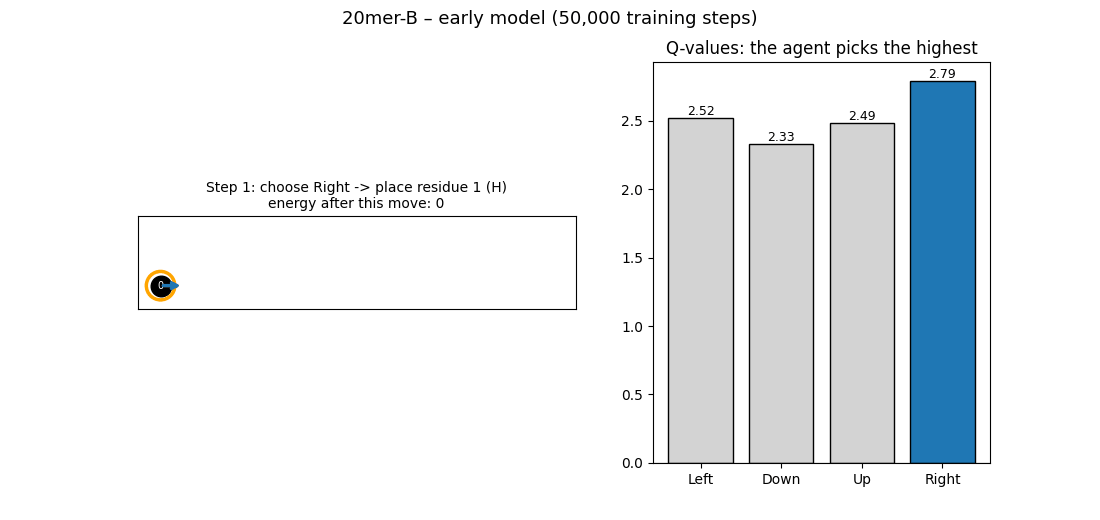

20mer-B – middle model (300,000 training steps): complete, energy -8, collisions 0 -> HP20_DQN\20mer-B\videos\dqn-20mer-B-middle.gif



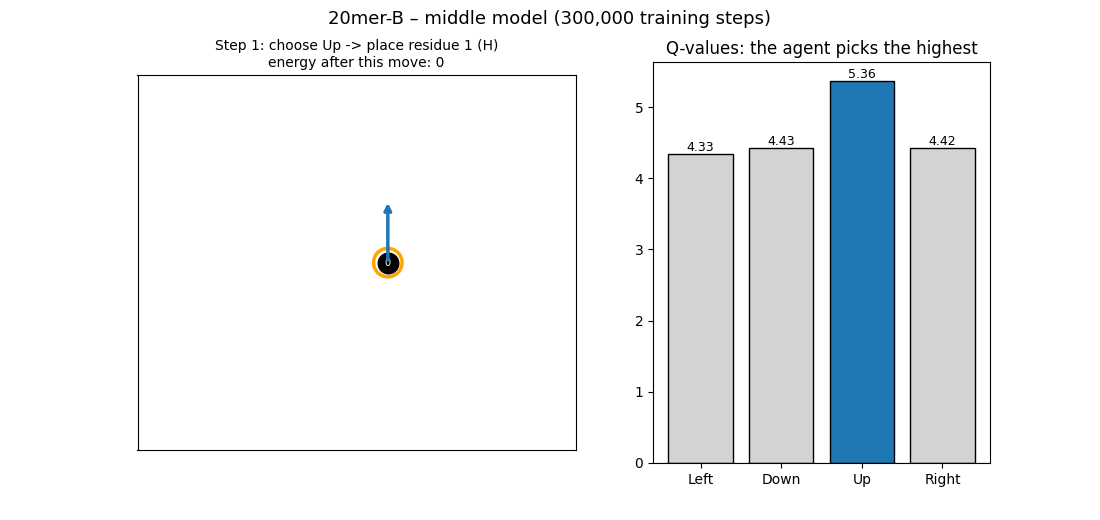

20mer-B – final model (500,000 training steps): complete, energy -8, collisions 0 -> HP20_DQN\20mer-B\videos\dqn-20mer-B-final.gif



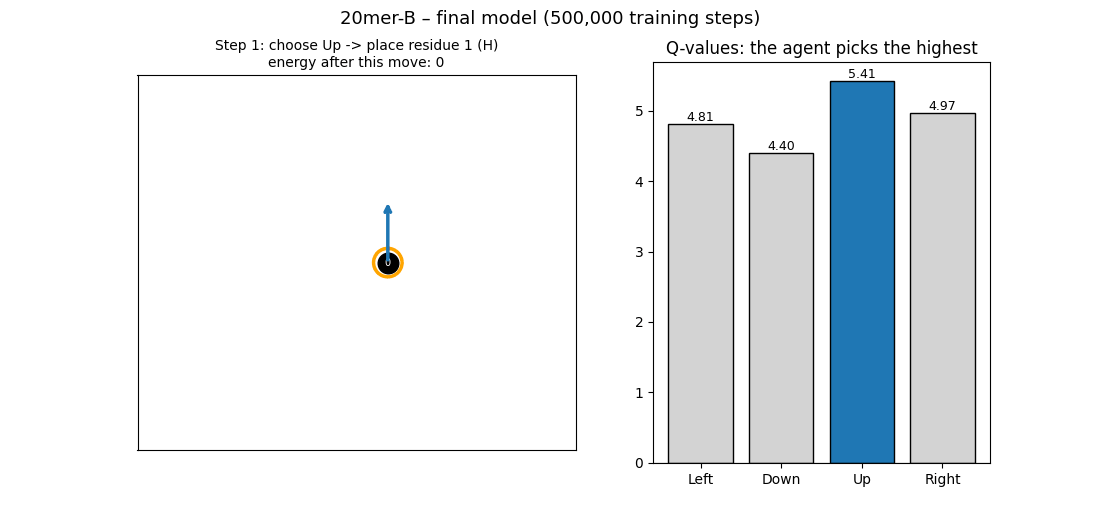

20mer-B – best model (500,000 training steps): complete, energy -8, collisions 0 -> HP20_DQN\20mer-B\videos\dqn-20mer-B-best.gif



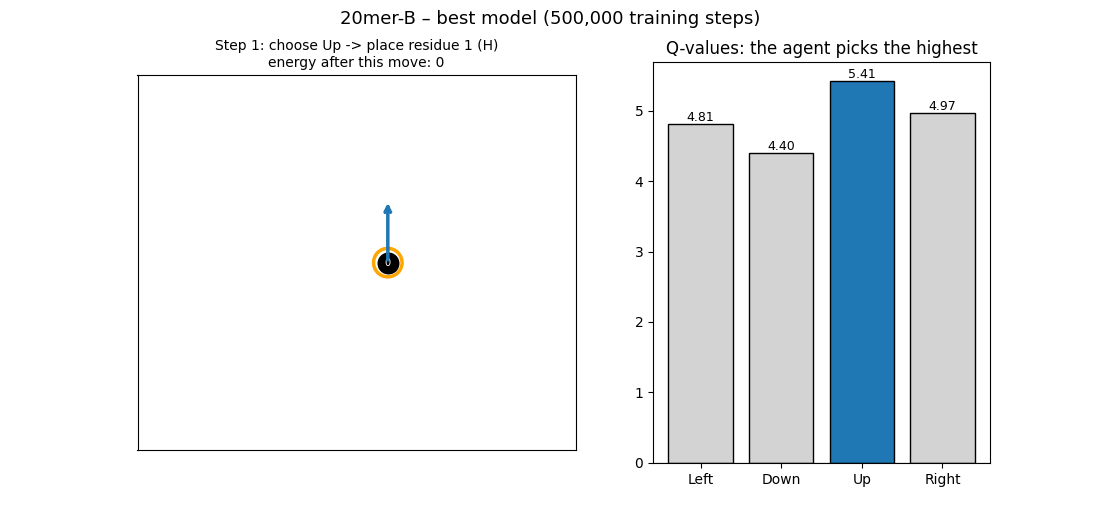

In [14]:
def pick_best_checkpoint(name):
    """Checkpoint whose greedy fold has the lowest energy (incomplete folds rank last;
    ties -> fewer collisions, then the later checkpoint)."""
    seq, models_dir = SEQUENCES[name], run_dirs(name)["models"]
    scores = []
    for identifier in get_model_identifiers(models_dir):
        model = DQN.load(os.path.join(models_dir, f"model_{identifier}"))
        _, info, status = record_decisions(model, seq)
        energy = info["energy"] if info["complete"] else 1
        scores.append((energy, info["collisions"], -int(identifier), identifier))
        print(f"  {int(identifier):>9,} steps: {status:<28} E = {info['energy']}")
    return min(scores)[3]


def decision_videos(name):
    seq, dirs = SEQUENCES[name], run_dirs(name)
    video_dir = os.path.join(BASE_DIR, name, "videos")
    os.makedirs(video_dir, exist_ok=True)
    identifiers = get_model_identifiers(dirs["models"])
    early, middle, final = find_key_identifiers(identifiers)
    print(f"{name}: scoring every checkpoint to find the best one")
    best = pick_best_checkpoint(name)
    for stage, identifier in [("early", early), ("middle", middle), ("final", final), ("best", best)]:
        model = DQN.load(os.path.join(dirs["models"], f"model_{identifier}"))
        title = f"{name} – {stage} model ({int(identifier):,} training steps)"
        path, info, status = make_decision_video(model, seq, title,
                                                 os.path.join(video_dir, f"dqn-{name}-{stage}"))
        show_video(path)

for name in SEQUENCES:
    decision_videos(name)

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


,Best known,Greedy energy,Best of 200 (eps=0.05),Mean of 200,% complete,Best during training,Step best found
Sequence,,,,,,,
20mer-A,-9,-8,-8,-6.888889,99.0,-9,340740
20mer-B,-10,-8,-8,-7.250000,100.0,-9,343216


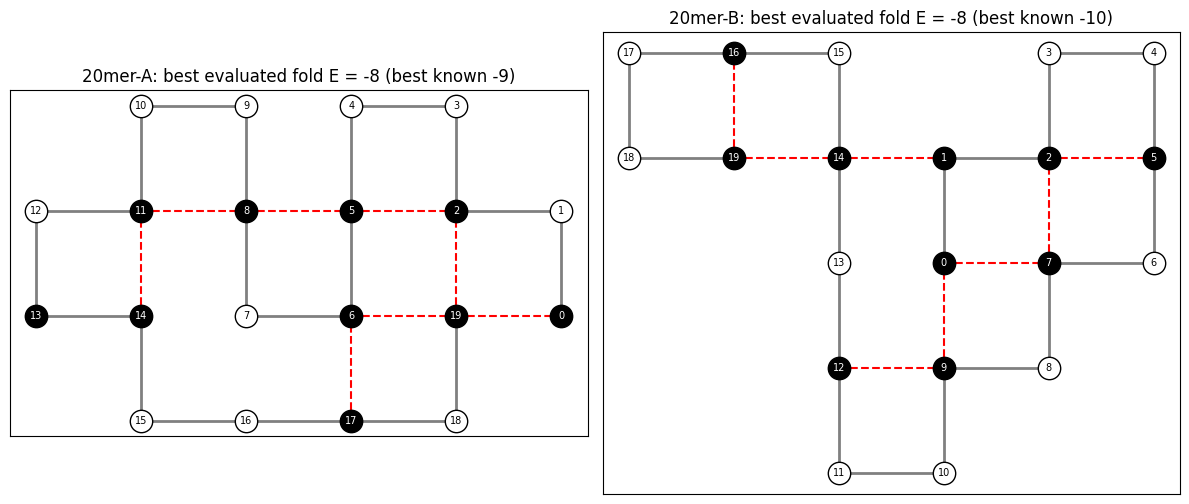

In [15]:
N_EVAL, EVAL_EPS = 200, 0.05
rows, best_folds = [], {}
for name, seq in SEQUENCES.items():
    models_dir = run_dirs(name)["models"]
    final_id = find_key_identifiers(get_model_identifiers(models_dir))[-1]
    model = DQN.load(os.path.join(models_dir, f'model_{final_id}'))

    g_env, g_info = run_episode(model, seq, eps=0.0)
    rng = np.random.default_rng(SEED)
    evals = [run_episode(model, seq, eps=EVAL_EPS, rng=rng) for _ in range(N_EVAL)]
    complete = [(e, i) for e, i in evals if i["complete"]]
    best_env, best_info = min(complete, key=lambda t: t[1]["energy"]) if complete else (g_env, g_info)
    best_folds[name] = (best_env, best_info)

    tracker = trackers.get(name)
    rows.append({
        "Sequence": name,
        "Best known": BEST_KNOWN[name],
        "Greedy energy": g_info["energy"] if g_info["complete"] else None,
        f"Best of {N_EVAL} (eps={EVAL_EPS})": best_info["energy"],
        f"Mean of {N_EVAL}": np.mean([i["energy"] for _, i in complete]) if complete else None,
        "% complete": 100 * len(complete) / N_EVAL,
        "Best during training": tracker.best_energy if tracker else None,
        "Step best found": tracker.best_timestep if tracker else None,
    })

results = pd.DataFrame(rows).set_index("Sequence")
display(results)

fig, axes = plt.subplots(1, len(SEQUENCES), figsize=(6 * len(SEQUENCES), 5))
for ax, (name, (env, info)) in zip(np.atleast_1d(axes), best_folds.items()):
    plot_fold(env.lattice.state, SEQUENCES[name],
              f"{name}: best evaluated fold E = {info['energy']} (best known {BEST_KNOWN[name]})", ax)
plt.tight_layout(); plt.show()

Best fold 

20mer-A: best training fold energy -9 (best known -9), actions RUULDLULULDDRDLDRRU
  (Up)
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************PP**********************
*****************HHPPP*******************
*****************PHHHH*******************
*****************PHHHP*******************
*****************PHP********

c:\Users\WorkPlace\Desktop\RL\RL Assignment3\gym-lattice-master\gym_lattice\envs\lattice2d_env.py:209: UserWarning: WARN: Your agent was trapped! Ending the episode.
  logger.warn('Your agent was trapped! Ending the episode.')


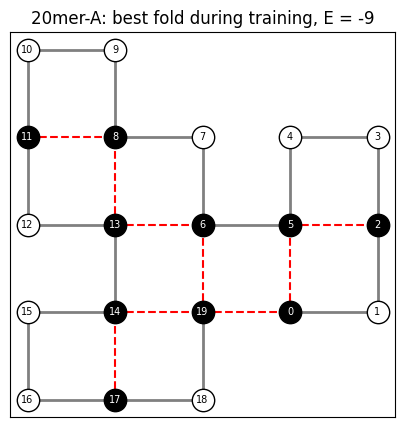

20mer-B: best training fold energy -9 (best known -10), actions LUURDRDDLDLULUULLDR
  (Right)
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*****************************************
*******************PP********************
****************PHPHHP*******************
****************PHHHHH*******************
******************PHHP**

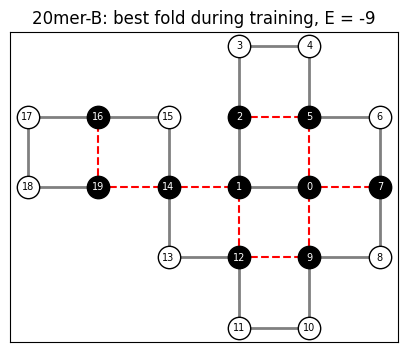

In [ ]:
STR_TO_ACTION = {v: k for k, v in ACTION_TO_STR.items()}

for name, tracker in trackers.items():
    env = GymLatticeCompat(SEQUENCES[name]); env.reset()
    for ch in tracker.best_actions:
        _, _, _, _, info = env.step(STR_TO_ACTION[ch])
    print(f"{name}: best training fold energy {info['energy']} (best known {BEST_KNOWN[name]}), actions {info['actions']}")
    env.render()
    plt.figure(figsize=(5, 5))
    plot_fold(env.lattice.state, SEQUENCES[name], f"{name}: best fold during training, E = {info['energy']}")
    plt.show()